# Sample non-dimensional planetary-geostrophic problem

This notebook specifies a PG problem with a broad zonal depth slope and an off-center Gaussian seamount, solves for surface pressure, samples the full 3D solution, writes VTK files, and plots the solution and diagnostic balances. The bathymetry remains strictly positive while varying in both horizontal directions, so the example exercises the full $H(x,y)$ API.

In [1]:
using Pkg
Pkg.activate(joinpath(@__DIR__, "..", "PlanetaryGeostrophy"))
using PlanetaryGeostrophy
using Gridap
using ForwardDiff
using Plots

  Activating project at `~/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/PlanetaryGeostrophy`


In [2]:
Lx, Ly = 2.0, 1.5
H0 = 1.0
boundary = rectangle_boundary(Lx, Ly)
parameters = PGParameters(0.02, 0.20; viscosity=1.0, diffusivity=1.0)

# A broad zonal slope plus a smooth off-center seamount exercises H(x, y).
depth_slope = 0.15
seamount_amplitude = 0.25
seamount_center = (-0.25Lx, 0.10Ly)
seamount_width = (0.25Lx, 0.30Ly)
seamount(x, y) = exp(
    -((x - seamount_center[1]) / seamount_width[1])^2 -
    ((y - seamount_center[2]) / seamount_width[2])^2
)
depth(x, y) = H0 * (
    1 + depth_slope * x / Lx - seamount_amplitude * seamount(x, y)
)
depth_x(x, y) = H0 * (
    depth_slope / Lx +
    2seamount_amplitude * (x - seamount_center[1]) /
    seamount_width[1]^2 * seamount(x, y)
)
depth_y(x, y) = H0 * (
    2seamount_amplitude * (y - seamount_center[2]) /
    seamount_width[2]^2 * seamount(x, y)
)

problem = PGProblem(
    parameters=parameters,
    depth=depth,
    depth_x=depth_x,
    depth_y=depth_y,
    coriolis=(x, y) -> 1.0 + 0.15y,
    coriolis_x=(x, y) -> 0.0,
    coriolis_y=(x, y) -> 0.15,
    wind_stress=(x, y) -> 1e-3 * cos(pi * y / Ly) + 0im,
    wind_stress_curl=(x, y) -> 1e-3 * pi / Ly * sin(pi * y / Ly),
    restoring_buoyancy=(x, y, z) -> 1e-2z + 2e-3 * sin(pi * x / Lx),
    surface_buoyancy=(x, y) -> 2e-3 * cos(pi * x / Lx) * cos(pi * y / Ly),
    boundary=boundary,
)

PGProblem{PGParameters{Float64}, typeof(depth), var"#29#30", var"#31#32", var"#33#34", var"#35#36", var"#37#38", var"#39#40", var"#41#42", typeof(depth_x), typeof(depth_y), Vector{Tuple{Float64, Float64}}, PlanetaryGeostrophy.var"#124#125"{Vector{Tuple{Float64, Float64}}}}(PGParameters{Float64}(0.02, 0.2, 1.0, 1.0), Main.depth, var"#29#30"(), var"#31#32"(), var"#33#34"(), var"#35#36"(), var"#37#38"(), var"#39#40"(), var"#41#42"(), Main.depth_x, Main.depth_y, [(-1.0, -0.75), (1.0, -0.75), (1.0, 0.75), (-1.0, 0.75)], PlanetaryGeostrophy.var"#124#125"{Vector{Tuple{Float64, Float64}}}([(-1.0, -0.75), (1.0, -0.75), (1.0, 0.75), (-1.0, 0.75)]), 1.0e-5)

In [3]:
solution = solve_pg(
    problem;
    mesh_file=joinpath(@__DIR__, "sample_pg_pressure.msh"),
    mesh_resolution=0.08,
    overwrite_mesh=true,
)

┌ Info: PG solve started
│   Ek = 0.02
│   Γ = 0.2
│   viscosity = 1.0
│   diffusivity = 1.0
│   pressure_order = 2
│   mesh_resolution = 0.08
│   mesh_file = /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/AnalyticalModel/sample_pg_pressure.msh
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/PlanetaryGeostrophy/src/PlanetaryGeostrophy.jl:237
┌ Info: Starting generating surface mesh
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/PlanetaryGeostrophy/src/PlanetaryGeostrophy.jl:16


Info    : Meshing 1D...
Info    : [  0%] Meshing curve 1 (Line)
Info    : [ 30%] Meshing curve 2 (Line)
Info    : [ 60%] Meshing curve 3 (Line)
Info    : [ 80%] Meshing curve 4 (Line)
Info    : Done meshing 1D (Wall 0.000156291s, CPU 0.000137s)
Info    : Meshing 2D...
Info    : Meshing surface 1 (Plane, Frontal-Delaunay)
Info    : Done meshing 2D (Wall 0.00786792s, CPU 0.007704s)
Info    : 606 nodes 1214 elements
Info    : Writing '/Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/AnalyticalModel/sample_pg_pressure.msh'...
Info    : Done writing '/Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/AnalyticalModel/sample_pg_pressure.msh'
Info    : Reading '/Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/Plane

┌ Info: Completed generating surface mesh
│   seconds = 0.057
│   allocated_mib = 3.54
│   gc_seconds = 0.0
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/PlanetaryGeostrophy/src/PlanetaryGeostrophy.jl:19
┌ Info: Starting loading analytical Green-function kernels
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/PlanetaryGeostrophy/src/PlanetaryGeostrophy.jl:16
┌ Info: Completed loading analytical Green-function kernels
│   seconds = 0.0
│   allocated_mib = 0.0
│   gc_seconds = 0.0
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/PlanetaryGeostrophy/src/PlanetaryGeostrophy.jl:19
┌ Info: Surface-pres

PGSolution{PGProblem{PGParameters{Float64}, typeof(depth), var"#29#30", var"#31#32", var"#33#34", var"#35#36", var"#37#38", var"#39#40", var"#41#42", typeof(depth_x), typeof(depth_y), Vector{Tuple{Float64, Float64}}, PlanetaryGeostrophy.var"#124#125"{Vector{Tuple{Float64, Float64}}}}, PlanetaryGeostrophy.VelocityFieldPrototype.SymbolicKernels{PlanetaryGeostrophy.VelocityFieldPrototype.var"#load_symbolic_kernels##0#load_symbolic_kernels##1", PlanetaryGeostrophy.VelocityFieldPrototype.var"#load_symbolic_kernels##2#load_symbolic_kernels##3", PlanetaryGeostrophy.VelocityFieldPrototype.var"#load_symbolic_kernels##4#load_symbolic_kernels##5", PlanetaryGeostrophy.VelocityFieldPrototype.var"#load_symbolic_kernels##6#load_symbolic_kernels##7", PlanetaryGeostrophy.VelocityFieldPrototype.var"#load_symbolic_kernels##8#load_symbolic_kernels##9", PlanetaryGeostrophy.VelocityFieldPrototype.var"#load_symbolic_kernels##10#load_symbolic_kernels##11"}, @NamedTuple{model::Gridap.Geometry.UnstructuredDiscr

In [4]:
x = range(-0.99Lx / 2, 0.99Lx / 2; length=64)
y = range(-0.99Ly / 2, 0.99Ly / 2; length=64)
z = range(-H0, 0.0; length=64)
fields = sample_solution(solution, x, y, z)

┌ Info: Solution sampling started
│   Nx = 64
│   Ny = 64
│   Nz = 64
│   grid_points = 262144
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/PlanetaryGeostrophy/src/PlanetaryGeostrophy.jl:1680
┌ Info: Starting sampling surface pressure and bathymetry
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/PlanetaryGeostrophy/src/PlanetaryGeostrophy.jl:16
┌ Info: Completed sampling surface pressure and bathymetry
│   seconds = 0.58
│   allocated_mib = 416.65
│   gc_seconds = 0.03
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/PlanetaryGeostrophy/src/PlanetaryGeostrophy.jl:19
┌ Info: Starting sampling 3D

PGFields{Vector{Float64}, Vector{Float64}, Vector{Float64}, @NamedTuple{surface_fields::@NamedTuple{seconds::Float64, allocated_mib::Float64, gc_seconds::Float64}, horizontal_velocity_and_buoyancy::@NamedTuple{seconds::Float64, allocated_mib::Float64, gc_seconds::Float64}, vertical_velocity::@NamedTuple{seconds::Float64, allocated_mib::Float64, gc_seconds::Float64}, total_seconds::Float64, wet_points::Int64, wet_points_per_second::Float64}}([-0.99, -0.9585714285714285, -0.9271428571428572, -0.8957142857142857, -0.8642857142857143, -0.8328571428571429, -0.8014285714285714, -0.77, -0.7385714285714285, -0.7071428571428572  …  0.7071428571428572, 0.7385714285714285, 0.77, 0.8014285714285714, 0.8328571428571429, 0.8642857142857143, 0.8957142857142857, 0.9271428571428572, 0.9585714285714285, 0.99], [-0.7424999999999999, -0.7189285714285714, -0.6953571428571428, -0.6717857142857142, -0.6482142857142856, -0.624642857142857, -0.6010714285714285, -0.5774999999999999, -0.5539285714285714, -0.5303

┌ Info: Writing sampled PG solution
│   prefix = /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/AnalyticalModel/sample_pg
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/PlanetaryGeostrophy/src/PlanetaryGeostrophy.jl:2610
┌ Info: Starting writing 3D VTK fields
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/PlanetaryGeostrophy/src/PlanetaryGeostrophy.jl:16
┌ Info: Completed writing 3D VTK fields
│   seconds = 4.872
│   allocated_mib = 50.6
│   gc_seconds = 0.0
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrop

(volume = "/Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/AnalyticalModel/sample_pg_3D_solution.vtr", surface = "/Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/AnalyticalModel/sample_pg_surface_solution.vtr", timings = (volume = (seconds = 4.871794375, allocated_mib = 50.59504699707031, gc_seconds = 0.0), surface = (seconds = 0.996612709, allocated_mib = 10.157913208007812, gc_seconds = 0.011644792), total_seconds = 5.869970083236694))

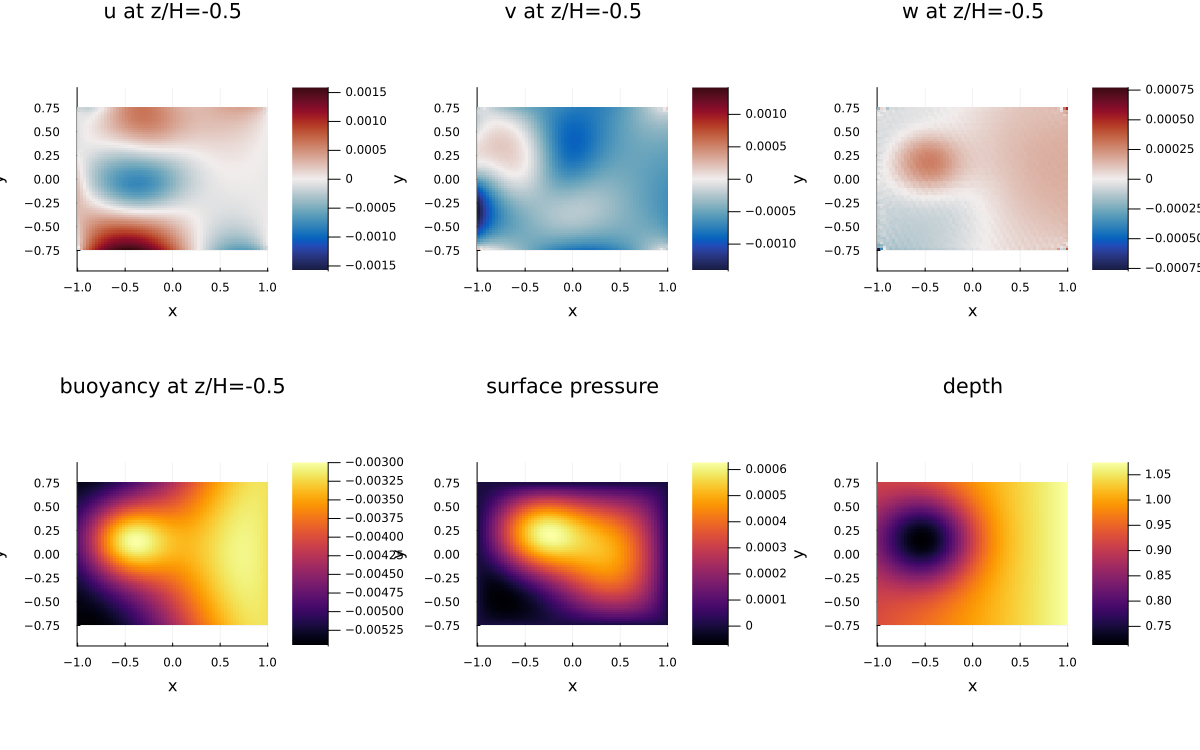

In [5]:
files = write_solution(fields, joinpath(@__DIR__, "sample_pg"))
figure = plot_solution(
    fields;
    sigma_level=0.5,
    output=joinpath(@__DIR__, "sample_pg_solution.png"),
)
display(files)
display(figure)

In [6]:
# The direct analytical diagnostic quadratures are more expensive than field sampling.
diagnostic_stride = 2
diagnostic_x = x[1:diagnostic_stride:end]
diagnostic_y = y[1:diagnostic_stride:end]
diagnostics = compute_diagnostics(solution, diagnostic_x, diagnostic_y)
display(performance_summary(diagnostics))

┌ Info: PG diagnostic calculation started
│   Nx = 32
│   Ny = 32
│   horizontal_points = 1024
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/PlanetaryGeostrophy/src/PlanetaryGeostrophy.jl:1766
┌ Info: Transport streamfunction solve started
│   finite_element_order = 2
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/AnalyticalModel/SurfacePressureTools.jl:370
┌ Info: Starting constructing streamfunction finite-element spaces
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/AnalyticalModel/SurfacePressureTools.jl:12
┌ Info: Completed constructing streamfunction finite-element spaces
│   seconds = 1

(streamfunction = (finite_element_setup = (seconds = 1.012711875, allocated_mib = 497.55419921875, gc_seconds = 0.02212), current_projection = (seconds = 15.81024175, allocated_mib = 2939.269973754883, gc_seconds = 0.139410959), operator_assembly = (seconds = 3.110286958, allocated_mib = 362.8893280029297, gc_seconds = 0.014607), linear_solve = (seconds = 0.012182334, allocated_mib = 6.07080078125, gc_seconds = 0.0), total_seconds = 20.01495099067688), bottom_stress_projection = (setup = (seconds = 0.082722417, allocated_mib = 14.833526611328125, gc_seconds = 0.0), interpolation = (seconds = 70.127616958, allocated_mib = 113526.91346740723, gc_seconds = 4.123778132), total_seconds = 70.24974393844604), sampling = (seconds = 6.134345625, allocated_mib = 1504.7166900634766, gc_seconds = 0.065185043), total_seconds = 96.84249305725098, wet_points = 1024, points_per_second = 166.92897052079618, transport_projection_relative_l2 = 0.7471687994606073)

┌ Info: Plotting bottom stress
│   stride = 2
│   arrow_scale = 0.7
│   arrowhead_size = 0.08
│   output = /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/AnalyticalModel/sample_pg_bottom_stress.png
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/PlanetaryGeostrophy/src/PlanetaryGeostrophy.jl:2978
┌ Info: Starting rendering bottom-stress plot
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/PlanetaryGeostrophy/src/PlanetaryGeostrophy.jl:16
┌ Info: Completed rendering bottom-stress plot
│   seconds = 0.009
│   allocated_mib = 1.25
│   gc_seconds = 0.0
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsH

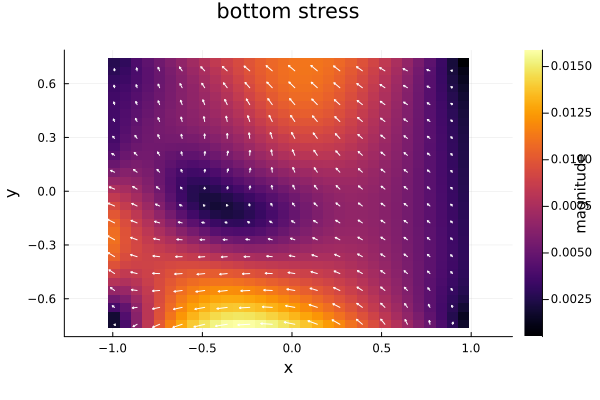

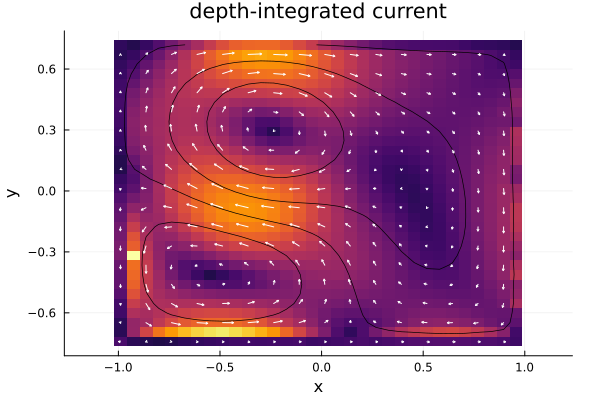

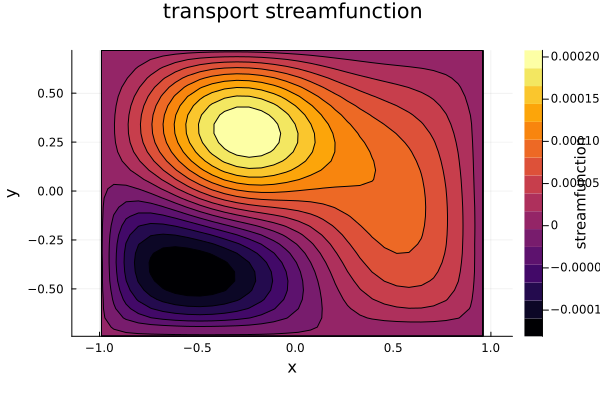

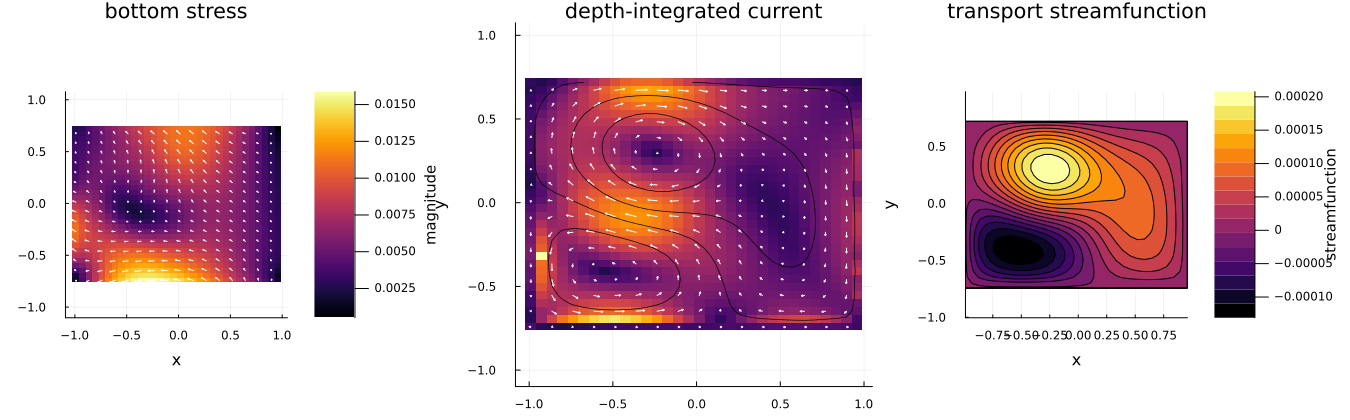

In [7]:
bottom_stress_figure = plot_bottom_stress(
    diagnostics;
    arrow_scale=0.70,
    output=joinpath(@__DIR__, "sample_pg_bottom_stress.png"),
)
transport_figure = plot_depth_integrated_current(
    diagnostics;
    arrow_scale=0.70,
    output=joinpath(@__DIR__, "sample_pg_transport.png"),
)
streamfunction_figure = plot_streamfunction(
    diagnostics;
    output=joinpath(@__DIR__, "sample_pg_streamfunction.png"),
)
diagnostic_figure = plot_diagnostics(
    diagnostics;
    arrow_scale=0.70,
    output=joinpath(@__DIR__, "sample_pg_diagnostics.png"),
)
display(bottom_stress_figure)
display(transport_figure)
display(streamfunction_figure)
display(diagnostic_figure)

## Depth-integrated momentum balance

Compute the terms corresponding to equations (32)--(33), together with bottom pressure $p_b$ and baroclinic potential energy $\chi$. The API consistently uses conventional oceanographic buoyancy, $\partial_z p=b$, with $p=p_s-\int_z^0 b\,dz$.

In [8]:
dim = compute_dim_diagnostics(solution, diagnostics)
display(performance_summary(dim))

┌ Info: DIM diagnostic calculation started
│   Nx = 32
│   Ny = 32
│   wet_points = 1024
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/PlanetaryGeostrophy/src/PlanetaryGeostrophy.jl:1860
┌ Info: Starting sampling depth-integrated momentum terms
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/PlanetaryGeostrophy/src/PlanetaryGeostrophy.jl:16
┌ Info: DIM diagnostic sampling progress
│   rows_completed = 1
│   rows_total = 32
│   percent = 3.1
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/PlanetaryGeostrophy/src/PlanetaryGeostrophy.jl:1885
┌ Info: DIM diagnostic sampling progress
│   rows_complet

(sampling = (seconds = 17.464173375, allocated_mib = 19316.2735748291, gc_seconds = 0.73243687), total_seconds = 17.465857982635498, x_relative_l2_residual = 6.568996293161015e-5, y_relative_l2_residual = 4.559164312309647e-5)

┌ Info: Plotting depth-integrated momentum balance
│   component = both
│   output = /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/AnalyticalModel/sample_pg_dim_balance.png
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/PlanetaryGeostrophy/src/PlanetaryGeostrophy.jl:3180
┌ Info: Starting rendering DIM balance plot
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/PlanetaryGeostrophy/src/PlanetaryGeostrophy.jl:16
┌ Info: Completed rendering DIM balance plot
│   seconds = 0.342
│   allocated_mib = 60.46
│   gc_seconds = 0.0
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/M

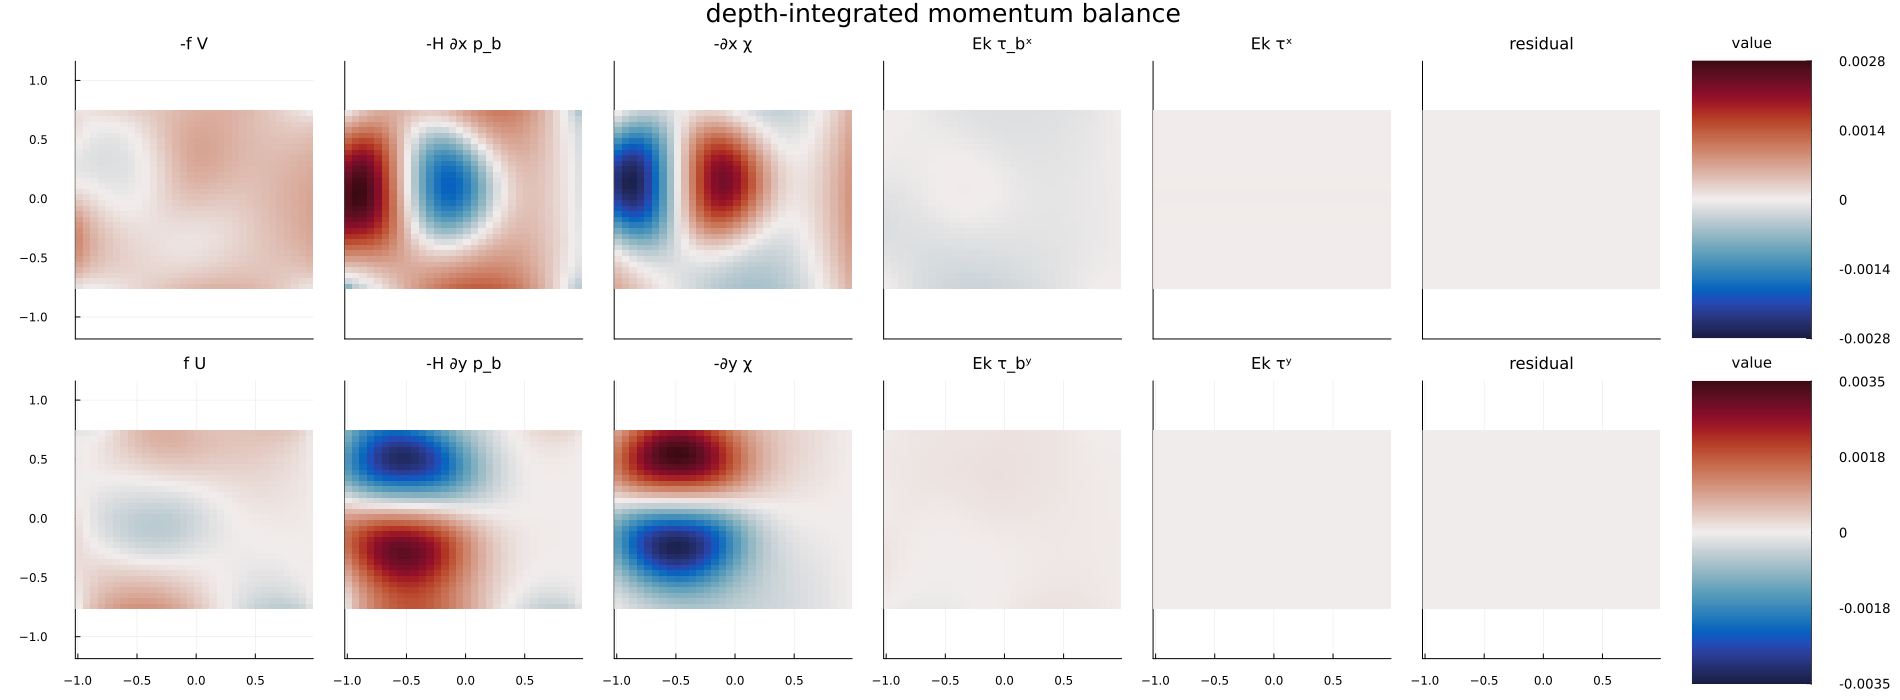

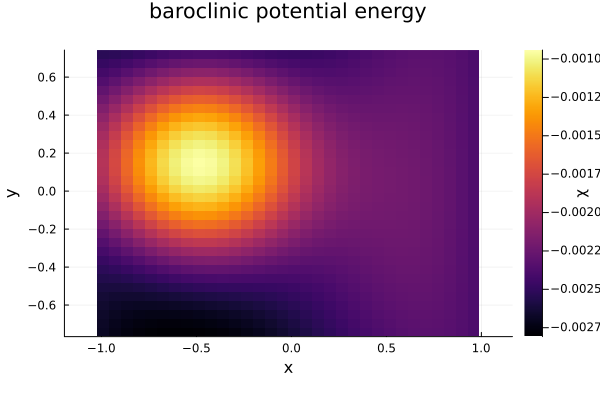

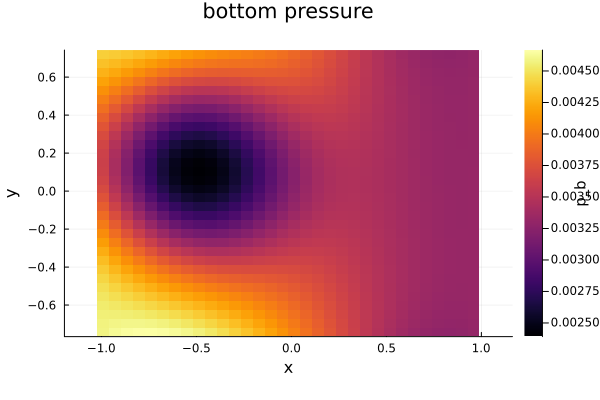

In [9]:
dim_balance_figure = plot_dim_balance(
    dim;
    output=joinpath(@__DIR__, "sample_pg_dim_balance.png"),
)
chi_figure = plot_baroclinic_potential_energy(
    dim;
    output=joinpath(@__DIR__, "sample_pg_chi.png"),
)
bottom_pressure_figure = plot_bottom_pressure(
    dim;
    output=joinpath(@__DIR__, "sample_pg_bottom_pressure.png"),
)
display(dim_balance_figure)
display(chi_figure)
display(bottom_pressure_figure)

## Barotropic vorticity balance

Compute and plot the transport-divergence, planetary-vorticity advection, bottom-pressure torque, boundary-stress curls, and closure residual in equation (36).

┌ Info: BV diagnostic calculation started
│   Nx = 32
│   Ny = 32
│   wet_points = 1024
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/PlanetaryGeostrophy/src/PlanetaryGeostrophy.jl:1943
┌ Info: Starting sampling barotropic vorticity terms
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/PlanetaryGeostrophy/src/PlanetaryGeostrophy.jl:16
┌ Info: BV diagnostic sampling progress
│   rows_completed = 1
│   rows_total = 32
│   percent = 3.1
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/PlanetaryGeostrophy/src/PlanetaryGeostrophy.jl:1955
┌ Info: BV diagnostic sampling progress
│   rows_completed = 4
│

(sampling = (seconds = 0.040705, allocated_mib = 89.10313415527344, gc_seconds = 0.0), total_seconds = 0.04100990295410156, relative_l2_residual = 0.032822954905550476)

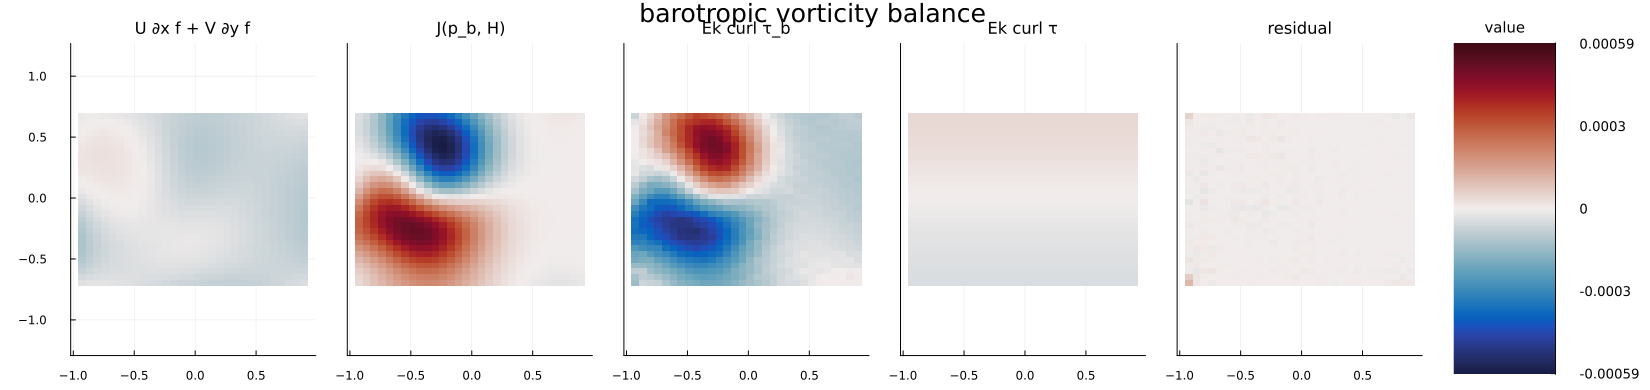

In [10]:
barotropic_vorticity = compute_barotropic_vorticity_diagnostics(
    solution, diagnostics,
)
display(performance_summary(barotropic_vorticity))

barotropic_vorticity_figure = plot_barotropic_vorticity_balance(
    barotropic_vorticity;
    output=joinpath(@__DIR__, "sample_pg_barotropic_vorticity_balance.png"),
)
display(barotropic_vorticity_figure)

## Depth-integrated vorticity balance

Compute and plot the planetary-vorticity advection, bottom vortex stretching, bottom-stress curl, surface-stress curl, and closure residual in equation (41).

┌ Info: Vorticity diagnostic calculation started
│   Nx = 32
│   Ny = 32
│   wet_points = 1024
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/PlanetaryGeostrophy/src/PlanetaryGeostrophy.jl:2061
┌ Info: Starting sampling depth-integrated vorticity terms
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/PlanetaryGeostrophy/src/PlanetaryGeostrophy.jl:16
┌ Info: Vorticity diagnostic sampling progress
│   rows_completed = 1
│   rows_total = 32
│   percent = 3.1
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/PlanetaryGeostrophy/src/PlanetaryGeostrophy.jl:2090
┌ Info: Vorticity diagnostic sampling progre

(sampling = (seconds = 0.305312458, allocated_mib = 243.1961212158203, gc_seconds = 0.021692125), total_seconds = 0.30564212799072266, relative_l2_residual = 0.12040464171143037)

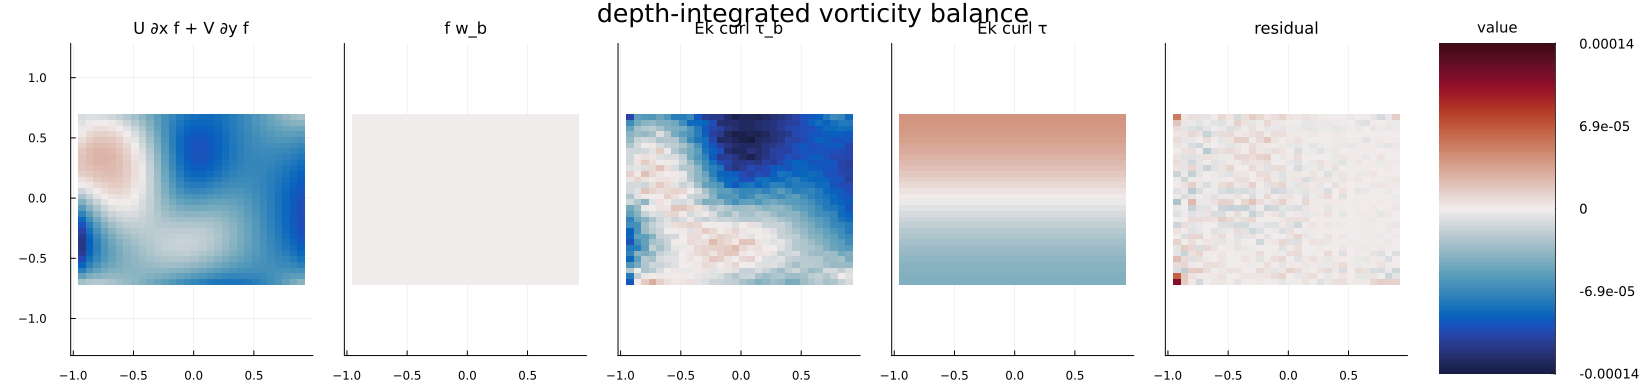

In [11]:
vorticity = compute_vorticity_diagnostics(solution, diagnostics)
display(performance_summary(vorticity))

vorticity_figure = plot_vorticity_balance(
    vorticity;
    output=joinpath(@__DIR__, "sample_pg_vorticity_balance.png"),
)
display(vorticity_figure)

## Geostrophic-contour vorticity balance

Compute and plot geostrophic-contour advection, JEBAR, the depth-weighted bottom- and surface-stress curls, and the closure residual in equation (43).

┌ Info: GCVB diagnostic calculation started
│   Nx = 32
│   Ny = 32
│   wet_points = 1024
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/PlanetaryGeostrophy/src/PlanetaryGeostrophy.jl:2191
┌ Info: Starting sampling geostrophic-contour vorticity terms
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/PlanetaryGeostrophy/src/PlanetaryGeostrophy.jl:16
┌ Info: GCVB diagnostic sampling progress
│   rows_completed = 1
│   rows_total = 32
│   percent = 3.1
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/PlanetaryGeostrophy/src/PlanetaryGeostrophy.jl:2207
┌ Info: GCVB diagnostic sampling progress
│   rows_

(sampling = (seconds = 0.09151775, allocated_mib = 119.52037048339844, gc_seconds = 0.014225376), total_seconds = 0.09178590774536133, relative_l2_residual = 0.038698312011674736)

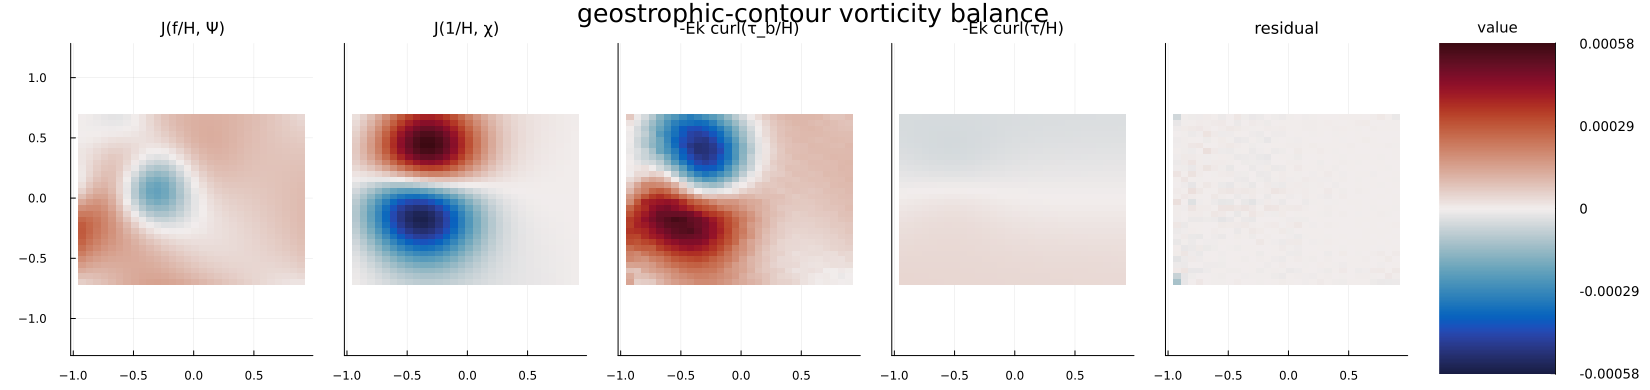

In [12]:
gcvb = compute_geostrophic_contour_vorticity_diagnostics(
    solution, diagnostics,
)
display(performance_summary(gcvb))

gcvb_figure = plot_geostrophic_contour_vorticity_balance(
    gcvb;
    output=joinpath(@__DIR__, "sample_pg_geostrophic_contour_vorticity_balance.png"),
)
display(gcvb_figure)

## Transport-divergence vorticity balance

Compute and plot the bottom-pressure torque, baroclinic torque, Coriolis-weighted bottom- and surface-stress curls, and closure residual in equation (46).

┌ Info: TDVB diagnostic calculation started
│   Nx = 32
│   Ny = 32
│   wet_points = 1024
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/PlanetaryGeostrophy/src/PlanetaryGeostrophy.jl:2313
┌ Info: Starting sampling transport-divergence vorticity terms
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/PlanetaryGeostrophy/src/PlanetaryGeostrophy.jl:16
┌ Info: TDVB diagnostic sampling progress
│   rows_completed = 1
│   rows_total = 32
│   percent = 3.1
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/PlanetaryGeostrophy/src/PlanetaryGeostrophy.jl:2331
┌ Info: TDVB diagnostic sampling progress
│   rows

(sampling = (seconds = 0.135925, allocated_mib = 206.13185119628906, gc_seconds = 0.017558), total_seconds = 0.13622117042541504, relative_l2_residual = 0.02465397797027033)

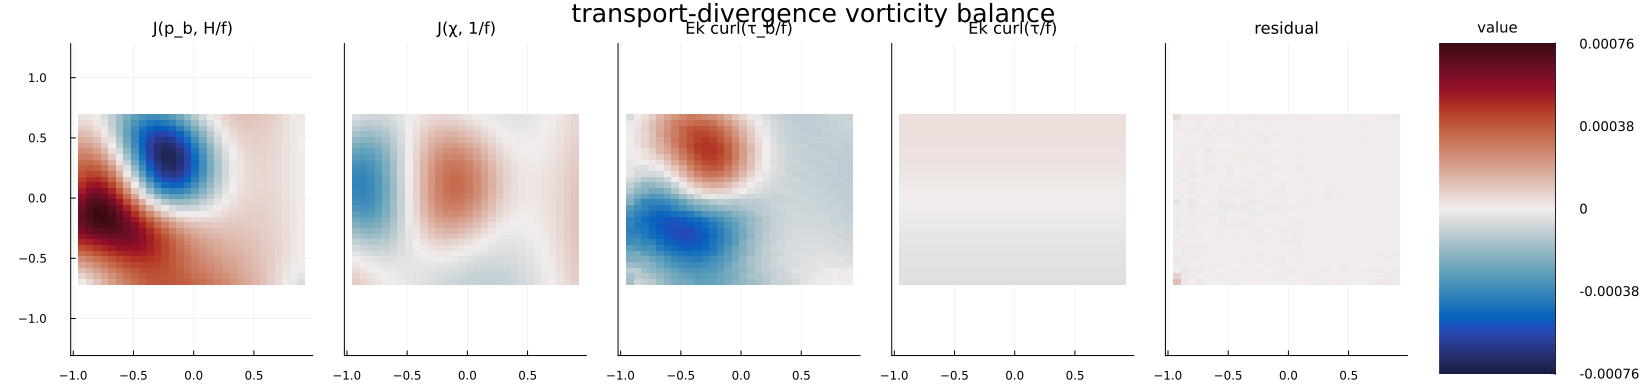

In [13]:
tdvb = compute_transport_divergence_vorticity_diagnostics(
    solution, diagnostics,
)
display(performance_summary(tdvb))

tdvb_figure = plot_transport_divergence_vorticity_balance(
    tdvb;
    output=joinpath(@__DIR__, "sample_pg_transport_divergence_vorticity_balance.png"),
)
display(tdvb_figure)

## Nøst & Isachsen (2003) comparison

Nøst & Isachsen split the depth-integrated transport into thermal-wind, ageostrophic, and bottom-geostrophic parts. Their equations (13), (16), and (23) argue that steep topography makes the bottom-geostrophic flow nearly parallel to contours of $q=f/H$. They then assume

$$
p_b=p_b(q),\qquad \mathbf{u}_{b,g}^{NI}=\frac{1}{f}\frac{dp_b}{dq}\,\mathbf{k}\times\nabla q.
$$

In the TDVB form used above, this closure predicts $J(p_b,H/f)=0$. The paper obtains $G(q)=dp_b/dq$ on each closed contour by integrating the forcing in its equation (16), then applying either linear bottom drag (equations 27--28) or quadratic bottom drag (equations 25--26). This PG model instead resolves a vertically viscous bottom boundary layer, so the calculation below first diagnoses one global effective $R$ and $C_D$ from the PG bottom stress. It then evaluates both Nøst--Isachsen contour-integral predictions independently of the PG bottom-pressure field. The comparison is restricted to closed $q$ contours, as required by their theory, and separately tests the theory's zero bottom-pressure torque against the accurate TDVB budget.

In [14]:
include(joinpath(@__DIR__, "NostIsachsenDiagnostics.jl"))

nost_isachsen = NostIsachsenDiagnostics.compute_nost_isachsen_diagnostics(
    solution, diagnostics, dim, tdvb,
)
display(nost_isachsen.metrics)

(comparison_points = 117, calibrated_linear_drag = 0.05751534621271551, calibrated_quadratic_drag = 15.477100110452552, stress_velocity_alignment = 0.36916650512715576, linear_relative_l2_velocity_error = 0.9175254479570937, quadratic_relative_l2_velocity_error = 0.6117845798165088, linear_speed_correlation = -0.20639816216811974, quadratic_speed_correlation = -0.3941611105019194, relative_l2_cross_q_velocity = 0.4442716758104122, pg_tdvb_relative_residual = 0.02465397797027033, ni_zero_pressure_torque_relative_residual = 0.9978253487376256)

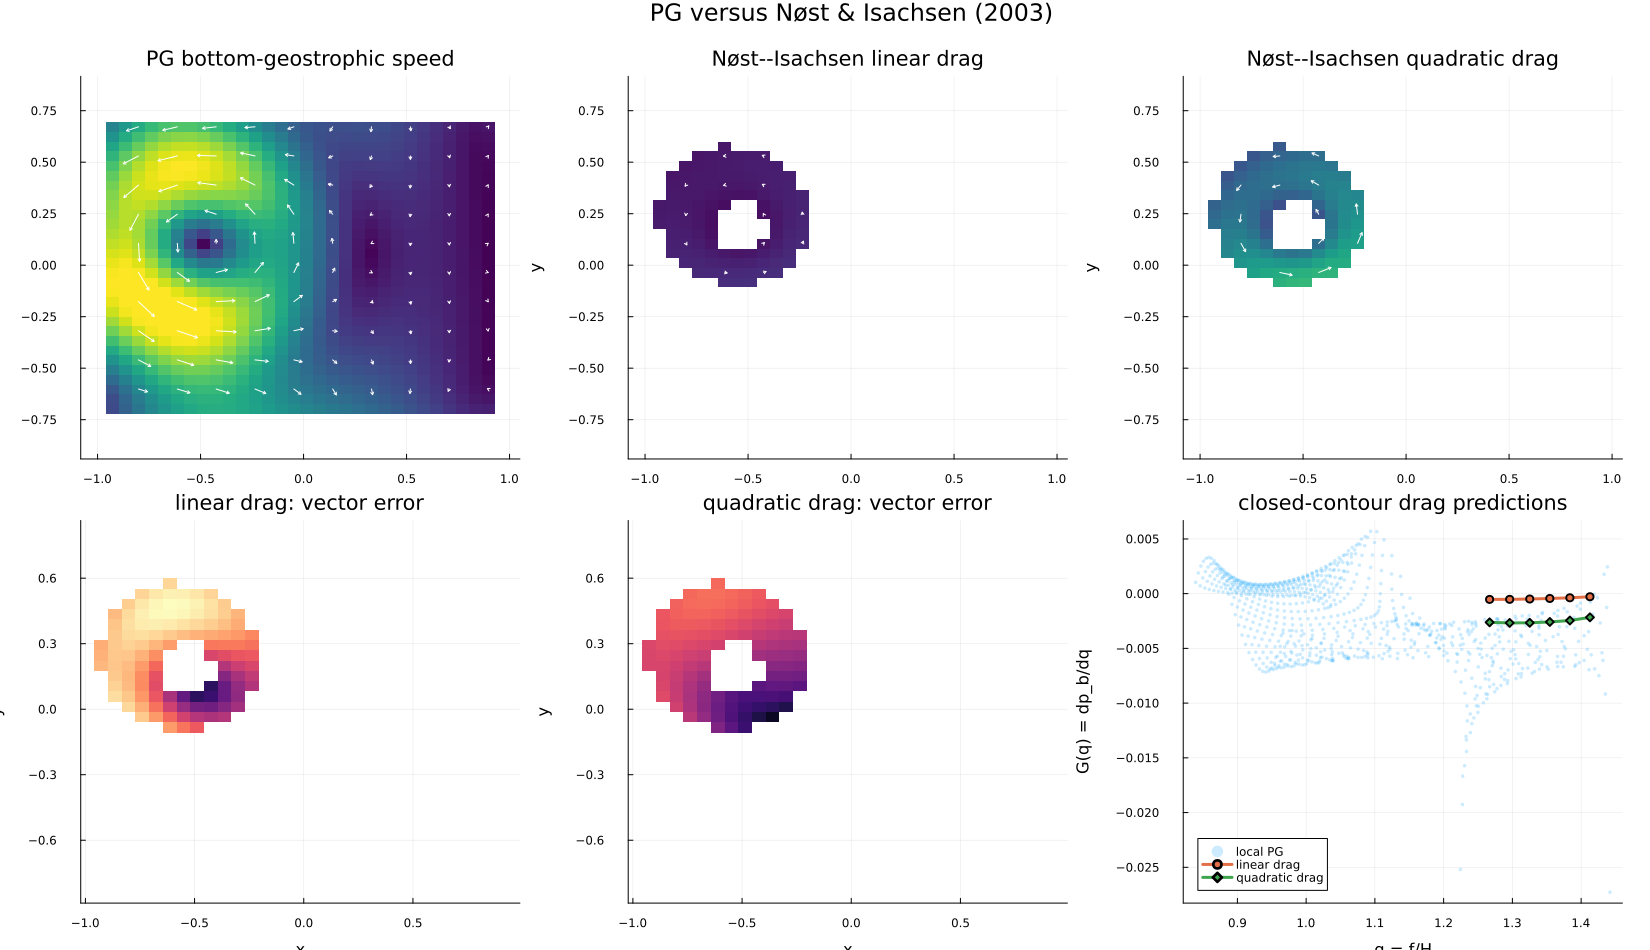

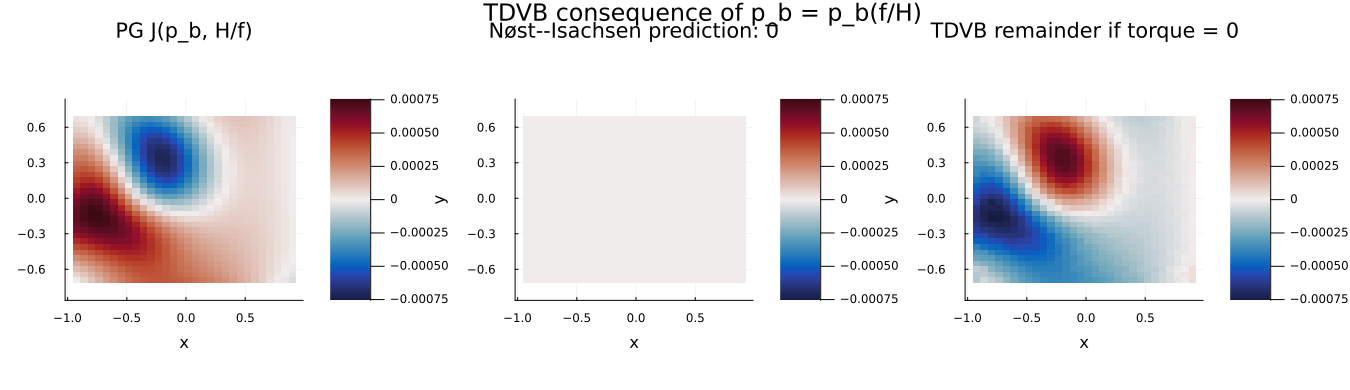

In [15]:
nost_isachsen_figures = NostIsachsenDiagnostics.plot_nost_isachsen_diagnostics(
    nost_isachsen;
    output_prefix=joinpath(@__DIR__, "sample_pg_nost_isachsen"),
)
display(nost_isachsen_figures.velocity)
display(nost_isachsen_figures.tdvb)

## Surface-pressure equation coefficients

Compute the inviscid and frictional components of the advection velocity, check their sum against the existing total field, and plot all three velocities on a common scale with the diffusivity and separate baroclinic and surface-stress source fields in the surface-pressure equation (74).

┌ Info: Surface-pressure equation diagnostic calculation started
│   Nx = 32
│   Ny = 32
│   wet_points = 1024
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/PlanetaryGeostrophy/src/PlanetaryGeostrophy.jl:2451
┌ Info: Starting sampling surface-pressure equation coefficients
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/PlanetaryGeostrophy/src/PlanetaryGeostrophy.jl:16
┌ Info: Surface-pressure equation diagnostic sampling progress
│   rows_completed = 1
│   rows_total = 32
│   percent = 3.1
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/PlanetaryGeostrophy/src/PlanetaryGeostrophy.jl:2481
┌ Info

(sampling = (seconds = 0.062818416, allocated_mib = 106.58547973632812, gc_seconds = 0.021716875), total_seconds = 0.06309890747070312, sampled_wet_points = 1024, wet_points = 900, points_per_second = 14327.008818560467, relative_l2_residual = 0.05476181776284554)

(advection_velocity_sum_error = 5.306561928016019e-15,)

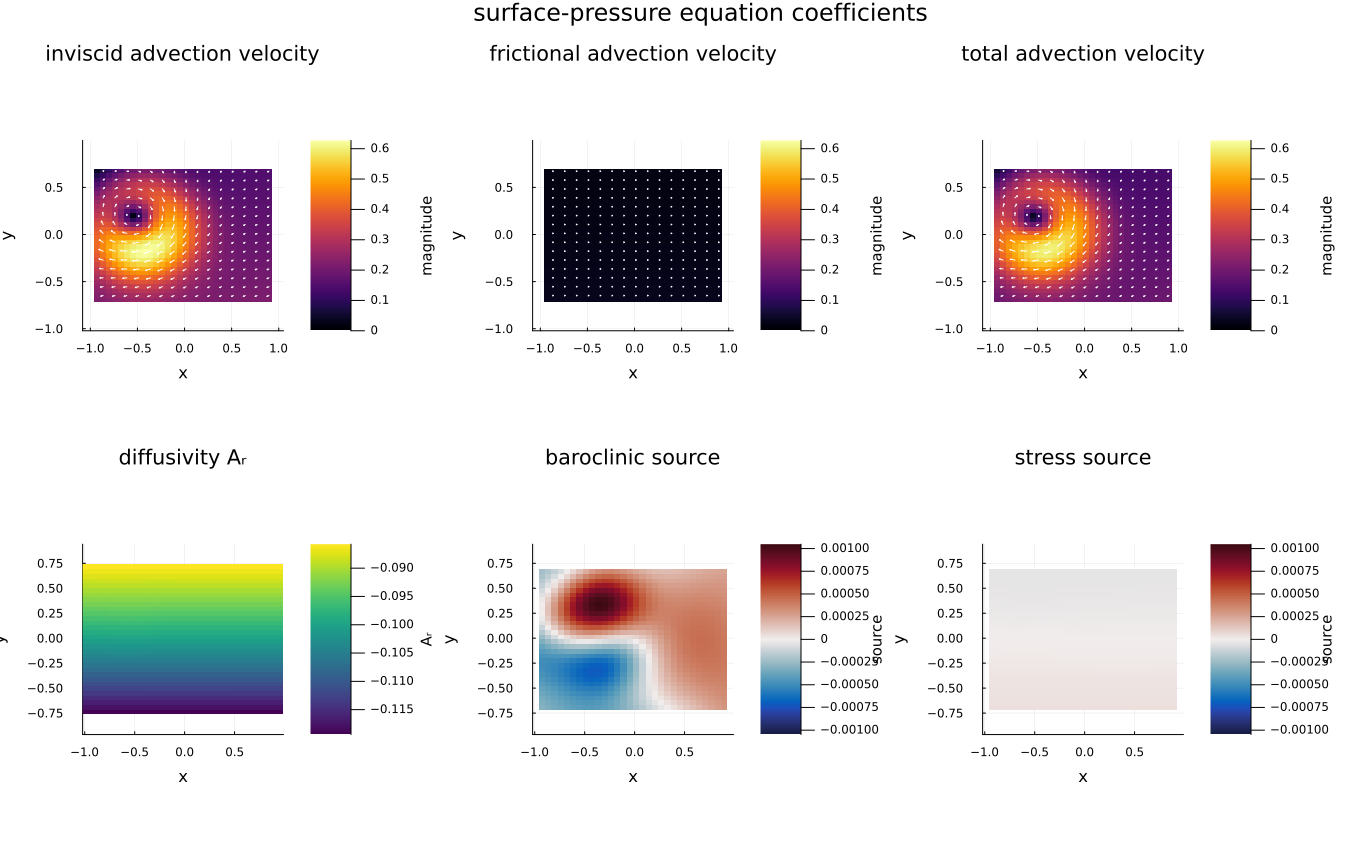

In [16]:
include(joinpath(@__DIR__, "SurfacePressureDiagnostics.jl"))
pressure_equation_diagnostics =
    SurfacePressureDiagnostics.compute_pressure_equation_diagnostics(
        solution, diagnostics,
    )
pressure_equation = pressure_equation_diagnostics.result
display(performance_summary(pressure_equation))
display(pressure_equation_diagnostics.metrics)

pressure_equation_figure =
    SurfacePressureDiagnostics.plot_pressure_equation_diagnostics(
        pressure_equation_diagnostics;
        arrow_scale=0.70,
        output=joinpath(@__DIR__, "sample_pg_surface_pressure_equation.png"),
    )
display(pressure_equation_figure)

## Spatial forcing-sensitivity kernels from the adjoint

For fixed geometry and parameters, the PG solution is linear in the forcing. The adjoint reverses the surface-pressure operator's advecting velocity and gives the functional derivative of a user-defined scalar cost $J$ with respect to forcing at every location. Here $J$ is the Gaussian-weighted transport speed, with `sensitivity_cost(U, V)` evaluated at the solved transport and automatically linearized there. The normalized Gaussian radius `target_radius` avoids a mesh-dependent point delta. Every panel marks the target center and radius; the resulting maps show $\delta J/\delta\tau^x(x,y)$, $\delta J/\delta\tau^y(x,y)$, $\delta J/\delta b_s(x,y)$, and horizontal slices of $\delta J/\delta B(x,y,z)$. For sloping topography, a separate bottom-boundary map records the distributional contribution from $B(x,y,-H)$.

In [17]:
target_x, target_y = 0.20Lx, -0.10Ly
# sensitivity_cost(U, V) = hypot(U, V)
# sensitivity_cost_label = "transport speed"
sensitivity_cost(U, V) = V
sensitivity_cost_label = "V"
target_radius = 0.10
sensitivity_x = range(-0.95Lx / 2, 0.95Lx / 2; length=49)
sensitivity_y = range(-0.95Ly / 2, 0.95Ly / 2; length=49)
sensitivity_z = [-0.75H0, -0.50H0, -0.25H0]

adjoint_sensitivity_diagnostics =
    SurfacePressureDiagnostics.compute_adjoint_sensitivity_diagnostics(
        solution, sensitivity_x, sensitivity_y, sensitivity_z;
        target=(target_x, target_y),
        cost=sensitivity_cost,
        cost_label=sensitivity_cost_label,
        target_radius=target_radius,
    )
adjoint_sensitivity = adjoint_sensitivity_diagnostics.result
display(performance_summary(adjoint_sensitivity))

┌ Info: Starting solving transport adjoint
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/PlanetaryGeostrophy/src/PlanetaryGeostrophy.jl:16
┌ Info: Starting constructing adjoint pressure finite-element spaces
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/AnalyticalModel/SurfacePressureTools.jl:12
┌ Info: Completed constructing adjoint pressure finite-element spaces
│   seconds = 0.001
│   allocated_mib = 0.67
│   gc_seconds = 0.0
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/AnalyticalModel/SurfacePressureTools.jl:15
┌ Info: Starting assembling adjoint surface-pressure operator
└ @ PlanetaryG

(adjoint = (seconds = 122.960249125, allocated_mib = 24801.65119934082, gc_seconds = 1.120247124), sampling = (seconds = 19.818399, allocated_mib = 3512.0216369628906, gc_seconds = 0.170615292), total_seconds = 142.95841717720032)

In [18]:
# Each range describes a local functional-derivative density, not a
# whole-pattern amplitude response.
display(adjoint_sensitivity_diagnostics.ranges)

(tau_x = (-0.4588310006783028, 0.4613232652436004), tau_y = (-0.49587324485717266, 1.397597684797429), surface_buoyancy = (-22.30699787293523, 18.614931955201058), interior_buoyancy = [(-37.7255415036446, 30.9052245627665), (-43.86084332175921, 32.971061539566506), (-35.318756129390486, 27.15713245007052)], bottom_buoyancy = (-0.6766108833903796, 0.5595950583743307))

┌ Info: Plotting transport adjoint sensitivity
│   cost_label = V
│   target = (x = 0.4, y = -0.15000000000000002)
│   radius = 0.1
│   levels = [1, 2, 3]
│   output = /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/AnalyticalModel/sample_pg_transport_adjoint_sensitivity.png
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/PlanetaryGeostrophy/src/PlanetaryGeostrophy.jl:3613
┌ Info: Starting rendering transport adjoint sensitivity plot
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/PlanetaryGeostrophy/src/PlanetaryGeostrophy.jl:16
┌ Info: Completed rendering transport adjoint sensitivity plot
│   seconds = 0.1
│   allocat

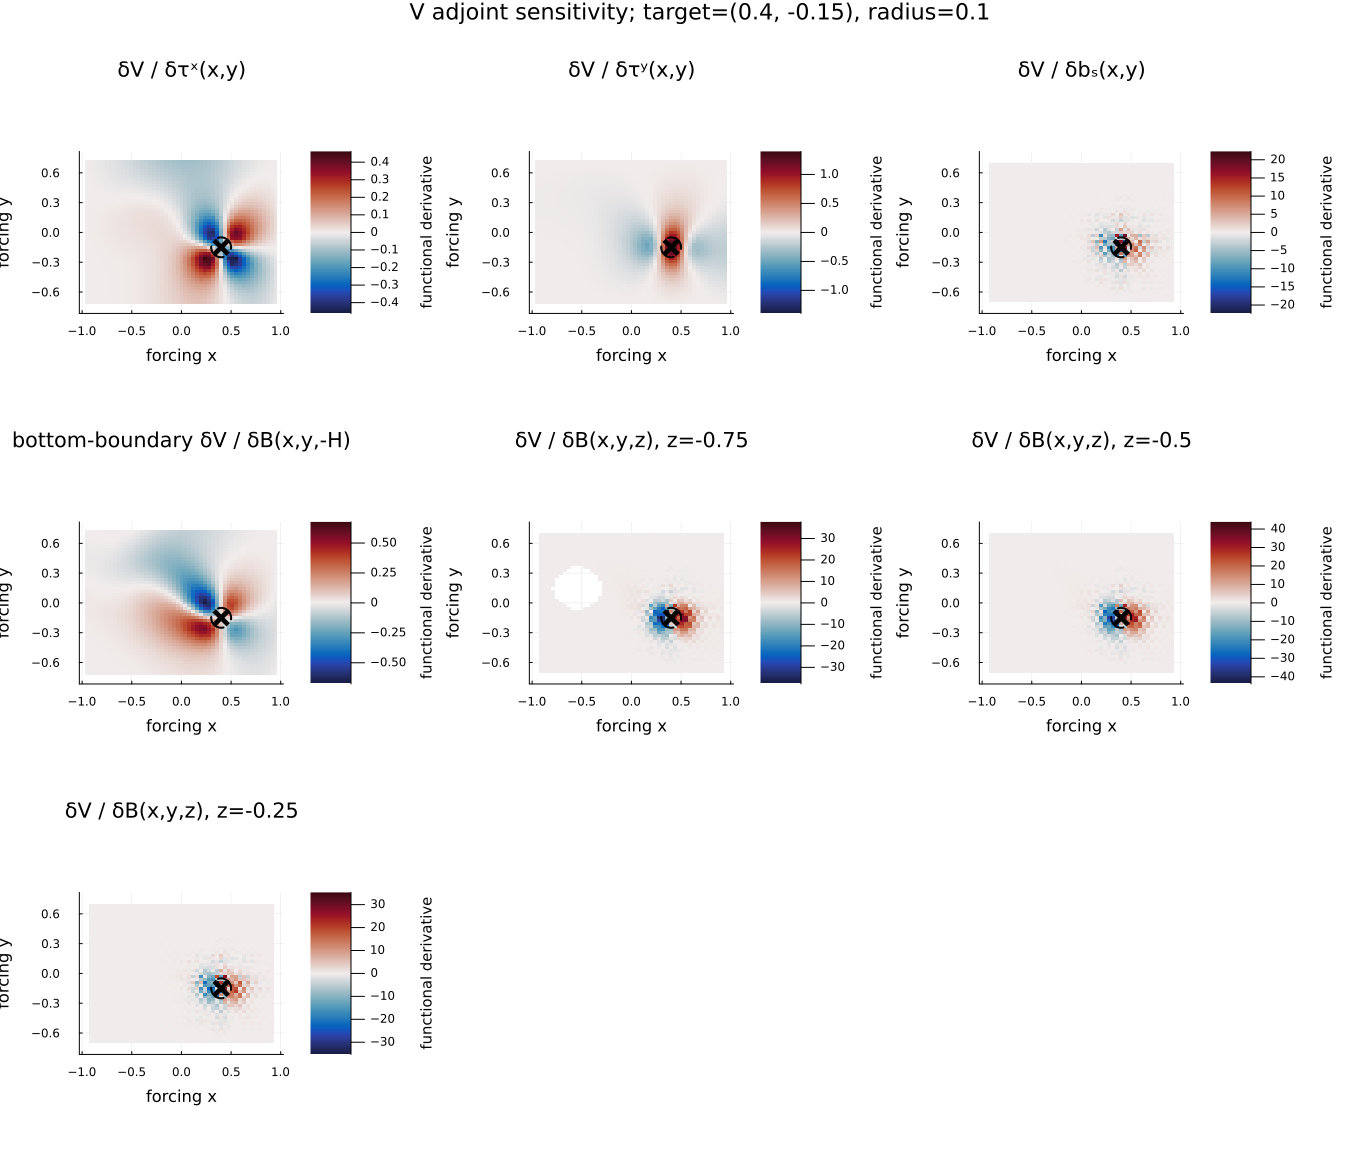

In [19]:
adjoint_sensitivity_figure =
    SurfacePressureDiagnostics.plot_adjoint_sensitivity_diagnostics(
        adjoint_sensitivity_diagnostics;
        output=joinpath(@__DIR__, "sample_pg_transport_adjoint_sensitivity.png"),
    )
display(adjoint_sensitivity_figure)

### Independent perturbation test

The following test does not reuse the adjoint equation to evaluate the perturbed costs. It solves the full forward PG response independently for smooth perturbation directions in $\tau^x$, $\tau^y$, $b_s$, and $B$. The linear cost $J=V$ makes the exact directional derivative independent of perturbation amplitude. Because the PG forward map is linear, each response can then be scaled exactly to form the centered finite difference

$$D_{\mathrm{FD}}(\epsilon)=\frac{J(q+\epsilon\,\delta q)-J(q-\epsilon\,\delta q)}{2\epsilon}.$$

This is compared with three adjoint predictions. The `exact_adjoint` value uses the finite-element quadrature and directly tests the pressure adjoint, independently of the sampled plotting grid. The `kernel_adjoint` pairing uses the plotted functional-derivative kernel after horizontal integration by parts. The `direct_adjoint` pairing instead uses the retained local and gradient coefficients before integration by parts, with perturbation derivatives computed by automatic differentiation. Differences between the exact and sampled predictions measure horizontal and vertical post-processing quadrature error, not error in the adjoint solve. The $B$ perturbation vanishes at the seabed; `bottom_adjoint` should therefore be zero. The test performs four additional forward solves in total, one for each perturbation direction. Because the demonstration uses the linear cost $J=V$, one centered perturbation amplitude is sufficient: the derivative is independent of amplitude. The modest sampled grid keeps the notebook practical, while the decisive exact finite-element identity remains independent of that grid.

In [20]:
# The sampled grid diagnoses post-processing quadrature only. The exact
# finite-element identity below provides the accuracy test, so this grid can
# remain modest enough for an interactive notebook run.
validation_x = range(-0.95Lx / 2, 0.95Lx / 2; length=17)
validation_y = range(-0.95Ly / 2, 0.95Ly / 2; length=17)
maximum_depth = maximum(
    problem.depth(x, y) for x in validation_x, y in validation_y
)
validation_z = range(-maximum_depth, 0.0; length=17)
validation_sensitivity = compute_transport_adjoint_sensitivity(
    solution, validation_x, validation_y, validation_z;
    target=(target_x, target_y),
    cost=sensitivity_cost,
    cost_label=sensitivity_cost_label,
    target_radius=target_radius,
)

function compact_bump(s)
    abs(s) >= 1 && return zero(s)
    exp(-1 / (1 - s^2))
end

perturbation_envelope(x, y) =
    compact_bump((x - target_x) / (0.25Lx)) *
    compact_bump((y - target_y) / (0.25Ly))

# Zero at the seabed: tests only the regular volume contribution
delta_B_volume(x, y, z) =
    1e-2 * perturbation_envelope(x, y) *
    (z + problem.depth(x, y)) / problem.depth(x, y)


perturbations = (
    tau_x=(
        wind_stress=(x, y) ->
            1e-3 * perturbation_envelope(x, y) + 0im,
        surface_buoyancy=(x, y) -> 0.0,
        restoring_buoyancy=(x, y, z) -> 0.0,
    ),
    tau_y=(
        wind_stress=(x, y) ->
            im * 1e-3 * perturbation_envelope(x, y),
        surface_buoyancy=(x, y) -> 0.0,
        restoring_buoyancy=(x, y, z) -> 0.0,
    ),
    surface_buoyancy=(
        wind_stress=(x, y) -> 0.0 + 0im,
        surface_buoyancy=(x, y) ->
            2e-3 * perturbation_envelope(x, y),
        restoring_buoyancy=(x, y, z) -> 0.0,
    ),
     restoring_buoyancy=(
        wind_stress=(x, y) -> 0.0 + 0im,
        surface_buoyancy=(x, y) -> 0.0,
        restoring_buoyancy=delta_B_volume,
    ),
)

forward_directions = solve_forcing_sensitivities(
    problem;
    restoring_buoyancy=
        perturbations.restoring_buoyancy.restoring_buoyancy,
    surface_buoyancy=
        perturbations.surface_buoyancy.surface_buoyancy,
    wind_stress_x=(x, y) ->
        real(perturbations.tau_x.wind_stress(x, y)),
    wind_stress_y=(x, y) ->
        imag(perturbations.tau_y.wind_stress(x, y)),
    mesh_file=solution.mesh_file,
    mesh_resolution=0.08,
)
forward_direction(name) = name === :tau_x ?
    forward_directions.wind_stress_x : name === :tau_y ?
    forward_directions.wind_stress_y : getproperty(forward_directions, name)
surface_x(field, x, y) = ForwardDiff.derivative(xx -> field(xx, y), x)
surface_y(field, x, y) = ForwardDiff.derivative(yy -> field(x, yy), y)
interior_x(field, x, y, z) =
    ForwardDiff.derivative(xx -> field(xx, y, z), x)
interior_y(field, x, y, z) =
    ForwardDiff.derivative(yy -> field(x, yy, z), y)
display((
    adjoint=performance_summary(validation_sensitivity),
    forward_directions=performance_summary(forward_directions),
))

# Pointwise check of the buoyancy-to-transport map, before the pressure adjoint.
prototype = PlanetaryGeostrophy.VelocityFieldPrototype
internal_parameters = PlanetaryGeostrophy.internal_parameters(problem.parameters)
function coefficient_transport(direction, x, y)
    H = problem.depth(x, y)
    interior = prototype.split_quadgk(
        z -> begin
            coefficients = prototype.buoyancy_transport_sensitivity_coefficients(
                solution.kernels,
                internal_parameters,
                problem.depth,
                problem.coriolis,
                problem.coriolis_x,
                problem.coriolis_y,
                problem.depth_x,
                problem.depth_y,
                x,
                y,
                z,
                gradient_step=problem.derivative_step,
            ).interior
            field = direction.restoring_buoyancy
            coefficients.value * field(x, y, z) +
                coefficients.gradient * complex(
                    interior_x(field, x, y, z),
                    interior_y(field, x, y, z),
                )
        end,
        -H,
        0.0,
    )
    bottom_coefficients =
        prototype.buoyancy_transport_sensitivity_coefficients(
            solution.kernels,
            internal_parameters,
            problem.depth,
            problem.coriolis,
            problem.coriolis_x,
            problem.coriolis_y,
            problem.depth_x,
            problem.depth_y,
            x,
            y,
            -H,
            gradient_step=problem.derivative_step,
        ).interior
    bottom = bottom_coefficients.gradient *
        complex(problem.depth_x(x, y), problem.depth_y(x, y)) *
        direction.restoring_buoyancy(x, y, -H)
    surface_coefficients =
        prototype.buoyancy_transport_sensitivity_coefficients(
            solution.kernels,
            internal_parameters,
            problem.depth,
            problem.coriolis,
            problem.coriolis_x,
            problem.coriolis_y,
            problem.depth_x,
            problem.depth_y,
            x,
            y,
            -H / 2,
            gradient_step=problem.derivative_step,
        ).surface
    surface_field = direction.surface_buoyancy
    surface = surface_coefficients.value * surface_field(x, y) +
        surface_coefficients.gradient * complex(
            surface_x(surface_field, x, y),
            surface_y(surface_field, x, y),
        )
    return interior + bottom + surface
end

transport_check_points = (
    (target_x, target_y),
    (target_x - 0.08Lx, target_y),
    (target_x, target_y + 0.08Ly),
)
transport_reconstruction_results = [
    begin
        response = forward_direction(name)
        forward = response.pressure.baroclinic_B_fn(Point(x, y))
        reconstructed = coefficient_transport(direction, x, y)
        relative_error = abs(forward - reconstructed) /
            max(abs(forward), abs(reconstructed), eps(Float64))
        (; forcing=name, x, y, forward, reconstructed, relative_error)
    end
    for name in (:surface_buoyancy, :restoring_buoyancy)
    for direction in (getproperty(perturbations, name),)
    for (x, y) in transport_check_points
]
display(transport_reconstruction_results)

┌ Info: Starting solving transport adjoint
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/PlanetaryGeostrophy/src/PlanetaryGeostrophy.jl:16
┌ Info: Starting constructing adjoint pressure finite-element spaces
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/AnalyticalModel/SurfacePressureTools.jl:12
┌ Info: Completed constructing adjoint pressure finite-element spaces
│   seconds = 0.001
│   allocated_mib = 0.67
│   gc_seconds = 0.0
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/AnalyticalModel/SurfacePressureTools.jl:15
┌ Info: Starting assembling adjoint surface-pressure operator
└ @ PlanetaryG

Info    : Reading '/Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/AnalyticalModel/sample_pg_pressure.msh'...
Info    : 9 entities
Info    : 606 nodes
Info    : 1210 elements
Info    : Done reading '/Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/AnalyticalModel/sample_pg_pressure.msh'


┌ Info: Solving forcing sensitivity
│   forcing = restoring_buoyancy
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/PlanetaryGeostrophy/src/PlanetaryGeostrophy.jl:529
┌ Info: PG solve started
│   Ek = 0.02
│   Γ = 0.2
│   viscosity = 1.0
│   diffusivity = 1.0
│   pressure_order = 2
│   mesh_resolution = 0.08
│   mesh_file = /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/AnalyticalModel/sample_pg_pressure.msh
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/PlanetaryGeostrophy/src/PlanetaryGeostrophy.jl:237
┌ Info: Starting reusing surface mesh
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkin

Info    : Reading '/Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/AnalyticalModel/sample_pg_pressure.msh'...
Info    : 9 entities
Info    : 606 nodes
Info    : 1210 elements
Info    : Done reading '/Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/AnalyticalModel/sample_pg_pressure.msh'


┌ Info: PG solve started
│   Ek = 0.02
│   Γ = 0.2
│   viscosity = 1.0
│   diffusivity = 1.0
│   pressure_order = 2
│   mesh_resolution = 0.08
│   mesh_file = /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/AnalyticalModel/sample_pg_pressure.msh
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/PlanetaryGeostrophy/src/PlanetaryGeostrophy.jl:237
┌ Info: Starting reusing surface mesh
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/PlanetaryGeostrophy/src/PlanetaryGeostrophy.jl:16
┌ Info: Completed reusing surface mesh
│   seconds = 0.0
│   allocated_mib = 0.0
│   gc_seconds = 0.0
└ @ PlanetaryGeostrophy /Users/twnh/Library/C

...

┌ Info: Starting solving surface-pressure linear system
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/AnalyticalModel/SurfacePressureTools.jl:12
┌ Info: Completed solving surface-pressure linear system
│   seconds = 0.017
│   allocated_mib = 4.45
│   gc_seconds = 0.004
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/AnalyticalModel/SurfacePressureTools.jl:15
┌ Info: Surface-pressure solve completed
│   seconds = 33.697
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/AnalyticalModel/SurfacePressureTools.jl:233
┌ Info: PG solve completed
│   seconds = 33.699
│   mesh_reused = true
└ @ PlanetaryGeo

Info    : Reading '/Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/AnalyticalModel/sample_pg_pressure.msh'...
Info    : 9 entities
Info    : 606 nodes
Info    : 1210 elements
Info    : Done reading '/Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/AnalyticalModel/sample_pg_pressure.msh'


┌ Info: Completed solving surface-pressure linear system
│   seconds = 0.023
│   allocated_mib = 4.45
│   gc_seconds = 0.0
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/AnalyticalModel/SurfacePressureTools.jl:15
┌ Info: Surface-pressure solve completed
│   seconds = 32.242
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/AnalyticalModel/SurfacePressureTools.jl:233
┌ Info: PG solve completed
│   seconds = 32.246
│   mesh_reused = true
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/PlanetaryGeostrophy/src/PlanetaryGeostrophy.jl:275
┌ Info: Solving forcing sensitivity
│   forcing = wind_stress_y
└ 

(adjoint = (adjoint = (seconds = 117.823292459, allocated_mib = 24331.752685546875, gc_seconds = 1.099582083), sampling = (seconds = 3.826918166, allocated_mib = 437.67706298828125, gc_seconds = 0.024121416), total_seconds = 121.65045094490051), forward_directions = (restoring_buoyancy = (mesh = (seconds = 1.1333e-5, allocated_mib = 0.00018310546875, gc_seconds = 0.0), kernels = (seconds = 0.0, allocated_mib = 0.0, gc_seconds = 0.0), surface_pressure = (mesh_load = (seconds = 0.002992584, allocated_mib = 2.0362396240234375, gc_seconds = 0.0), finite_element_setup = (seconds = 0.000573875, allocated_mib = 0.68182373046875, gc_seconds = 0.0), operator_assembly = (seconds = 69.46068475, allocated_mib = 30966.759704589844, gc_seconds = 1.375850911), linear_solve = (seconds = 0.003899125, allocated_mib = 6.07080078125, gc_seconds = 0.0), total_seconds = 69.48711895942688), total_seconds = 69.48754096031189), surface_buoyancy = (mesh = (seconds = 2.1959e-5, allocated_mib = 0.00018310546875, 

6-element Vector{@NamedTuple{forcing::Symbol, x::Float64, y::Float64, forward::ComplexF64, reconstructed::ComplexF64, relative_error::Float64}}:
 (forcing = :surface_buoyancy, x = 0.4, y = -0.15000000000000002, forward = -6.115740360925222e-8 + 4.184283488919037e-7im, reconstructed = -6.115741294517459e-8 + 4.1842834546308265e-7im, relative_error = 2.351921104986866e-8)
 (forcing = :surface_buoyancy, x = 0.24000000000000002, y = -0.15000000000000002, forward = 1.1895783658147623e-5 - 7.438658148988512e-5im, reconstructed = 1.189578364558914e-5 - 7.43865814674256e-5im, relative_error = 3.4158487665741453e-10)
 (forcing = :surface_buoyancy, x = 0.4, y = -0.030000000000000027, forward = -0.00010174773049134752 - 1.511210288971739e-5im, reconstructed = -0.00010174773042392652 - 1.5112102881996852e-5im, relative_error = 6.597225108876712e-10)
 (forcing = :restoring_buoyancy, x = 0.4, y = -0.15000000000000002, forward = 1.0100637574634774e-6 - 1.247605721660089e-5im, reconstructed = 1.010063

In [21]:
# Evaluate J directly from base + epsilon * response with the same finite-element
# quadrature and normalized target weight used by the adjoint problem.
transport_at(forward_solution, x, y) = begin
    pressure = forward_solution.pressure
    point = Point(x, y)
    pressure.A_fn(point) * pressure.gradps(x, y) + pressure.B_fn(point)
end
target_weight(x, y) = exp(
        -(
            (x - target_x)^2 +
            (y - target_y)^2
        ) / (2target_radius^2),
    )
trapezoid(x, values) = sum(
    (x[i + 1] - x[i]) * (values[i + 1] + values[i]) / 2
    for i in 1:(length(x) - 1)
)
function trapezoid2(x, y, values)
    trapezoid(y, [trapezoid(x, view(values, :, j)) for j in eachindex(y)])
end
validation_domain = Triangulation(solution.pressure.model)
validation_measure = Measure(validation_domain, 2 * solution.pressure.order)
validation_normalization = sum(∫(
    point -> target_weight(point[1], point[2]),
)validation_measure)
function centered_forward_derivative(base_solution, response_solution, epsilon)
    sum(∫(
        point -> begin
            base = transport_at(base_solution, point[1], point[2])
            response = transport_at(response_solution, point[1], point[2])
            target_weight(point[1], point[2]) *
                (
                    sensitivity_cost(
                        real(base + epsilon * response),
                        imag(base + epsilon * response),
                    ) - sensitivity_cost(
                        real(base - epsilon * response),
                        imag(base - epsilon * response),
                    )
                ) / (2epsilon * validation_normalization)
        end,
    )validation_measure)
end
finite_kernel_product(kernel, value) = isfinite(kernel) ? kernel * value : 0.0

function adjoint_predictions(name, direction)
    sensitivity = validation_sensitivity
    if name === :tau_x || name === :tau_y
        kernel = name === :tau_x ?
            sensitivity.wind_stress_x : sensitivity.wind_stress_y
        component = name === :tau_x ? real : imag
        values = [
            finite_kernel_product(
                kernel[i, j],
                component(direction.wind_stress(
                    sensitivity.x[i], sensitivity.y[j],
                )),
            )
            for i in eachindex(sensitivity.x), j in eachindex(sensitivity.y)
        ]
        prediction = trapezoid2(sensitivity.x, sensitivity.y, values)
        return (;
            kernel=prediction,
            direct=prediction,
            direct_volume=0.0,
            bottom=0.0,
        )
    elseif name === :surface_buoyancy
        field = direction.surface_buoyancy
        kernel_values = [
            finite_kernel_product(
                sensitivity.surface_buoyancy[i, j],
                field(sensitivity.x[i], sensitivity.y[j]),
            )
            for i in eachindex(sensitivity.x), j in eachindex(sensitivity.y)
        ]
        direct_values = [
            begin
                x, y = sensitivity.x[i], sensitivity.y[j]
                finite_kernel_product(
                    sensitivity.surface_buoyancy_local[i, j], field(x, y),
                ) + finite_kernel_product(
                    sensitivity.surface_buoyancy_gradient_x[i, j],
                    surface_x(field, x, y),
                ) + finite_kernel_product(
                    sensitivity.surface_buoyancy_gradient_y[i, j],
                    surface_y(field, x, y),
                )
            end
            for i in eachindex(sensitivity.x), j in eachindex(sensitivity.y)
        ]
        kernel = trapezoid2(sensitivity.x, sensitivity.y, kernel_values)
        direct = trapezoid2(sensitivity.x, sensitivity.y, direct_values)
        return (; kernel, direct, direct_volume=0.0, bottom=0.0)
    end

    field = direction.restoring_buoyancy
    kernel_by_depth = [
        trapezoid2(sensitivity.x, sensitivity.y, [
            finite_kernel_product(
                sensitivity.restoring_buoyancy[i, j, k],
                field(sensitivity.x[i], sensitivity.y[j], sensitivity.z[k]),
            )
            for i in eachindex(sensitivity.x), j in eachindex(sensitivity.y)
        ])
        for k in eachindex(sensitivity.z)
    ]
    direct_by_depth = [
        trapezoid2(sensitivity.x, sensitivity.y, [
            begin
                x, y, z = sensitivity.x[i], sensitivity.y[j], sensitivity.z[k]
                finite_kernel_product(
                    sensitivity.restoring_buoyancy_local[i, j, k],
                    field(x, y, z),
                ) + finite_kernel_product(
                    sensitivity.restoring_buoyancy_gradient_x[i, j, k],
                    interior_x(field, x, y, z),
                ) + finite_kernel_product(
                    sensitivity.restoring_buoyancy_gradient_y[i, j, k],
                    interior_y(field, x, y, z),
                )
            end
            for i in eachindex(sensitivity.x), j in eachindex(sensitivity.y)
        ])
        for k in eachindex(sensitivity.z)
    ]
    bottom_values = [
        finite_kernel_product(
            sensitivity.bottom_restoring_buoyancy[i, j],
            field(
                sensitivity.x[i],
                sensitivity.y[j],
                -problem.depth(sensitivity.x[i], sensitivity.y[j]),
            ),
        )
        for i in eachindex(sensitivity.x), j in eachindex(sensitivity.y)
    ]
    kernel_volume = trapezoid(sensitivity.z, kernel_by_depth)
    direct_volume = trapezoid(sensitivity.z, direct_by_depth)
    bottom = trapezoid2(sensitivity.x, sensitivity.y, bottom_values)
    return (;
        kernel=kernel_volume + bottom,
        direct=direct_volume + bottom,
        direct_volume,
        bottom,
    )
end

adjoint_predictions (generic function with 1 method)

In [22]:
# J=V is linear, so one centered difference fully tests amplitude behavior.
epsilon_values = [0.1]
validation_results = NamedTuple[]
for name in propertynames(perturbations)
    direction = getproperty(perturbations, name)
    predictions = adjoint_predictions(name, direction)
    response_solution = forward_direction(name)
    exact_identity = transport_adjoint_identity(
        validation_sensitivity, response_solution,
    )
    for epsilon in epsilon_values
        finite_difference = centered_forward_derivative(
            solution, response_solution, epsilon,
        )
        kernel_relative_error = abs(finite_difference - predictions.kernel) /
            max(abs(finite_difference), abs(predictions.kernel), eps(Float64))
        direct_relative_error = abs(finite_difference - predictions.direct) /
            max(abs(finite_difference), abs(predictions.direct), eps(Float64))
        exact_relative_error = abs(finite_difference - exact_identity.adjoint) /
            max(abs(finite_difference), abs(exact_identity.adjoint), eps(Float64))
        push!(validation_results, (;
            forcing=name,
            epsilon,
            finite_difference,
            exact_adjoint=exact_identity.adjoint,
            kernel_adjoint=predictions.kernel,
            direct_adjoint=predictions.direct,
            direct_volume_adjoint=predictions.direct_volume,
            bottom_adjoint=predictions.bottom,
            exact_relative_error,
            kernel_relative_error,
            direct_relative_error,
        ))
    end
end
validation_summary = [
    begin
        rows = filter(row -> row.forcing === name, validation_results)
        (
            forcing=name,
            exact_adjoint=first(rows).exact_adjoint,
            kernel_adjoint=first(rows).kernel_adjoint,
            direct_adjoint=first(rows).direct_adjoint,
            direct_volume_adjoint=first(rows).direct_volume_adjoint,
            bottom_adjoint=first(rows).bottom_adjoint,
            minimum_exact_error=minimum(
                getproperty.(rows, :exact_relative_error),
            ),
            minimum_kernel_error=minimum(
                getproperty.(rows, :kernel_relative_error),
            ),
            minimum_direct_error=minimum(
                getproperty.(rows, :direct_relative_error),
            ),
        )
    end
    for name in propertynames(perturbations)
]
display(validation_results)
display(validation_summary)

4-element Vector{NamedTuple}:
 (forcing = :tau_x, epsilon = 0.1, finite_difference = -3.0780896464232976e-7, exact_adjoint = -3.0780896464233743e-7, kernel_adjoint = -3.3144047199801935e-7, direct_adjoint = -3.3144047199801935e-7, direct_volume_adjoint = 0.0, bottom_adjoint = 0.0, exact_relative_error = 2.493831228538648e-14, kernel_relative_error = 0.07129940170924814, direct_relative_error = 0.07129940170924814)
 (forcing = :tau_y, epsilon = 0.1, finite_difference = 6.834351518504804e-6, exact_adjoint = 6.834351518504791e-6, kernel_adjoint = 6.841647443744347e-6, direct_adjoint = 6.841647443744347e-6, direct_volume_adjoint = 0.0, bottom_adjoint = 0.0, exact_relative_error = 1.9830011844391904e-15, kernel_relative_error = 0.0010663988899652969, direct_relative_error = 0.0010663988899652969)
 (forcing = :surface_buoyancy, epsilon = 0.1, finite_difference = -7.999034612975972e-6, exact_adjoint = -7.99903461297466e-6, kernel_adjoint = -5.5598079409473065e-6, direct_adjoint = 3.2078288313

4-element Vector{@NamedTuple{forcing::Symbol, exact_adjoint::Float64, kernel_adjoint::Float64, direct_adjoint::Float64, direct_volume_adjoint::Float64, bottom_adjoint::Float64, minimum_exact_error::Float64, minimum_kernel_error::Float64, minimum_direct_error::Float64}}:
 (forcing = :tau_x, exact_adjoint = -3.0780896464233743e-7, kernel_adjoint = -3.3144047199801935e-7, direct_adjoint = -3.3144047199801935e-7, direct_volume_adjoint = 0.0, bottom_adjoint = 0.0, minimum_exact_error = 2.493831228538648e-14, minimum_kernel_error = 0.07129940170924814, minimum_direct_error = 0.07129940170924814)
 (forcing = :tau_y, exact_adjoint = 6.834351518504791e-6, kernel_adjoint = 6.841647443744347e-6, direct_adjoint = 6.841647443744347e-6, direct_volume_adjoint = 0.0, bottom_adjoint = 0.0, minimum_exact_error = 1.9830011844391904e-15, minimum_kernel_error = 0.0010663988899652969, minimum_direct_error = 0.0010663988899652969)
 (forcing = :surface_buoyancy, exact_adjoint = -7.99903461297466e-6, kernel_ad

┌ Warning: JSON-RPC endpoint has been blocked writing to its peer; outgoing messages are queueing up and will not be delivered until the peer resumes reading
│   blocked_seconds = 645.9
│   queued_messages = 2
└ @ VSCodeServer.JSONRPC /Users/twnh/.vscode/extensions/julialang.language-julia-1.243.2/scripts/packages/JSONRPC/src/core.jl:414


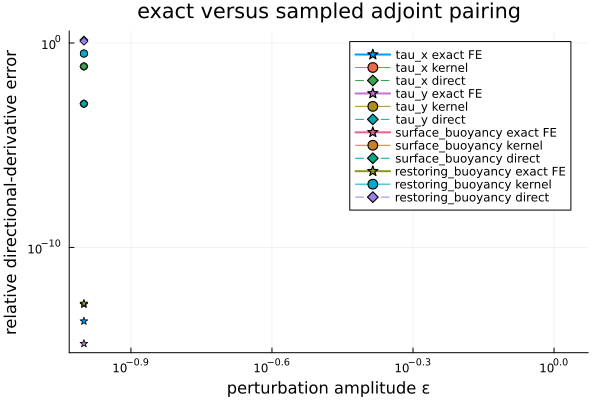

In [23]:
adjoint_error_figure = Plots.plot(
    xscale=:log10,
    yscale=:log10,
    xlabel="perturbation amplitude ε",
    ylabel="relative directional-derivative error",
    title="exact versus sampled adjoint pairing",
    legend=:best,
)
for name in propertynames(perturbations)
    rows = filter(row -> row.forcing === name, validation_results)
    Plots.plot!(
        adjoint_error_figure,
        getproperty.(rows, :epsilon),
        getproperty.(rows, :exact_relative_error);
        marker=:star5,
        linewidth=2,
        label="$(name) exact FE",
    )
    Plots.plot!(
        adjoint_error_figure,
        getproperty.(rows, :epsilon),
        getproperty.(rows, :kernel_relative_error);
        marker=:circle,
        label="$(name) kernel",
    )
    Plots.plot!(
        adjoint_error_figure,
        getproperty.(rows, :epsilon),
        getproperty.(rows, :direct_relative_error);
        marker=:diamond,
        linestyle=:dash,
        label="$(name) direct",
    )
end
display(adjoint_error_figure)